# ¿Cuánto viven los discos?
**MapReduce, balanceo de carga y Spark Streaming sobre Backblaze Drive Stats (Q2 2026)**

Este notebook reúne los resultados de cada parte del ejercicio. Las **tablas y gráficos se calculan aquí mismo** a partir de los archivos de `resultados/`, así que se ejecuta en segundos sin necesitar Spark ni Kafka. Los **fragmentos de código en bloques** muestran la idea central de cada script; el código completo está en `src/`.

| Parte | Tema | Script |
|---|---|---|
| Datos | Descarga y recorte del trimestre | `src/descargar_datos.py` |
| A | MapReduce con RDD | `src/parte_a_mapreduce.py` |
| B | Balanceo de carga | `src/parte_b_balanceo.py` |
| C | Streaming con Kafka | `src/parte_c_producer.py`, `src/parte_c_streaming.py` |
| D | MongoDB | `src/parte_d_agregados.py`, `src/parte_d_mongo.py` |
| Reto | Kaplan-Meier | `src/reto_km_agregados.py` |

**Entorno:** Docker con Spark 3.5.3 (1 master + 2 workers, 4 cores en total), Kafka 3.8 en modo KRaft (sin Zookeeper) y MongoDB 7.0 (`docker-compose.yml`).

**Fuente de datos:** [Backblaze Drive Stats](https://www.backblaze.com/drivestats), trimestre Q2 2026 (`data_Q2_2026.zip`). Datos gratuitos citando a Backblaze.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTADOS = RAIZ / "resultados"
DATOS = RAIZ / "data" / "slim"

# Paleta de referencia (primeros tres slots categóricos) y tintas
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, TENUE, REJILLA, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": TINTA, "axes.labelcolor": TINTA2, "xtick.color": TENUE, "ytick.color": TENUE,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
pd.set_option("display.width", 140)


def miles(n):
    """Entero con punto como separador de miles (formato local)."""
    return f"{n:,.0f}".replace(",", ".")


def afr(fallas, dias_disco):
    """Tasa de falla anualizada (%) = fallas / (días-disco / 365) x 100."""
    return fallas / (dias_disco / 365.0) * 100


def fallas_txt(n):
    n = int(n)
    return f"{n} falla" + ("" if n == 1 else "s")


def solo_rejilla(ax, eje):
    ax.grid(False)
    ax.grid(axis=eje, visible=True)


print("Resultados en:", RESULTADOS.relative_to(RAIZ))
print("Archivos disponibles:", ", ".join(sorted(p.name for p in RESULTADOS.glob("*.csv"))))

Resultados en: resultados
Archivos disponibles: km_vida_por_disco.csv, parte_a_afr_por_modelo.csv, parte_b_particiones.csv, parte_b_tiempos.csv, parte_c_ventanas.csv, parte_d_ventanas.csv


## Datos: Backblaze Drive Stats, Q2 2026

Una fila por disco y por día. El ZIP del trimestre pesa 2,1 GB, pero no hace falta bajarlo completo: el servidor acepta peticiones por rango, así que se lee el directorio central del ZIP y se pide solo cada CSV. Además se descartan las columnas que el ejercicio no usa (de 197 quedan 5).

```python
# src/descargar_datos.py (fragmento)
COLUMNAS = ["date", "serial_number", "model", "capacity_bytes", "failure"]

with RemoteZip(URL, timeout=60) as z:                       # lee solo lo que pide, por rangos
    for info in dias:                                        # un CSV por día
        with z.open(info.filename) as crudo:
            lector = csv.reader(io.TextIOWrapper(crudo, encoding="utf-8", newline=""))
            cabecera = next(lector)
            idx = [cabecera.index(c) for c in COLUMNAS]      # se queda con 5 de 197 columnas
            for fila in lector:
                escritor.writerow([fila[i] for i in idx])
```

La descarga es reanudable (salta los días que ya existen) y reintenta si la red falla.

In [2]:
if DATOS.exists():
    archivos = sorted(DATOS.glob("*.csv"))
    peso = sum(f.stat().st_size for f in archivos) / 1e9
    muestra = pd.read_csv(archivos[0], nrows=3)
    print(f"{len(archivos)} archivos diarios, {archivos[0].stem} a {archivos[-1].stem}, {peso:.2f} GB (solo 5 columnas)")
    display(muestra)
else:
    print("La carpeta data/slim no está disponible; ejecuta src/descargar_datos.py para generarla.")

91 archivos diarios, 2026-04-01 a 2026-06-30, 1.84 GB (solo 5 columnas)


,date,serial_number,model,capacity_bytes,failure
0,2026-04-01,6190A04TF97G,TOSHIBA MG07ACA14TA,14000519643136,0
1,2026-04-01,85X2A08JF4MJ,TOSHIBA MG10ACA20TE,20000588955648,0
2,2026-04-01,8190A0V2FVKG,TOSHIBA MG08ACA16TA,16000900661248,0


---
## Parte A. MapReduce

Con RDD, cada fila emite el par `(modelo, (1, falla))` y `reduceByKey` suma los dos componentes. Así se obtienen los **días-disco** y las **fallas** por modelo, y con ellos la tasa de falla anualizada:

$$\text{AFR}(\%) = \frac{\text{fallas}}{\text{días-disco} / 365} \times 100$$

```python
# src/parte_a_mapreduce.py (fragmento)
por_modelo = (filas.map(lambda r: (r[2], (1, r[3])))                       # (modelo, (1, falla))
                   .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])))  # suma días-disco y fallas

# La AFR se calcula después, sobre los totales: una división no se puede combinar parcialmente
def afr(fallas, dias_disco):
    return fallas / (dias_disco / 365.0) * 100 if dias_disco else 0.0

rdd = {m: (d, f) for m, (d, f) in por_modelo.collect()}                  # modelo -> (días-disco, fallas)
tabla = [(m, d, f, afr(f, d)) for m, (d, f) in rdd.items()]               # modelo, días-disco, fallas, AFR

# Verificación: el mismo cálculo con DataFrames debe dar exactamente lo mismo
df = spark.read.csv(rutas, header=True).groupBy("model").agg(
    F.count("*").alias("dias_disco"), F.sum(F.col("failure").cast("int")).alias("fallas"))
assert rdd == dfd        # RDD == groupBy en los 81 modelos
```

Los resultados de abajo son de la corrida con los **91 días del trimestre**.

In [3]:
a = pd.read_csv(RESULTADOS / "parte_a_afr_por_modelo.csv")
tot_dias, tot_fallas = int(a["dias_disco"].sum()), int(a["fallas"].sum())
afr_total = afr(tot_fallas, tot_dias)

comparacion = pd.DataFrame({
    "Nuestro cálculo": [miles(tot_dias), miles(tot_fallas), f"{afr_total:.2f} %".replace(".", ",")],
    "Backblaze (según el enunciado)": [miles(31_553_350), miles(1_498), "1,73 %"],
}, index=["Días-disco", "Fallas", "AFR"])
print(f"{len(a)} modelos")
display(comparacion)

81 modelos


,Nuestro cálculo,Backblaze (según el enunciado)
Días-disco,31.968.003,31.553.350
Fallas,1.522,1.498
AFR,"1,74 %","1,73 %"


**Verificación.** El script ya compara el RDD con un `groupBy` de DataFrames de Spark y lo imprime en su salida. Aquí se repite la comprobación de forma independiente: un `groupBy` de pandas sobre los 91 CSV, comparado con el resultado del RDD.

In [4]:
if DATOS.exists():
    por_dia = [pd.read_csv(f, usecols=["model", "failure"]).groupby("model")["failure"].agg(dias_disco="size", fallas="sum")
               for f in sorted(DATOS.glob("*.csv"))]
    gb = pd.concat(por_dia).groupby(level=0).sum()
    rdd = a.set_index("modelo")[["dias_disco", "fallas"]]
    iguales = len(gb) == len(rdd) and bool((gb.loc[rdd.index].to_numpy() == rdd.to_numpy()).all())
    print(f"groupBy independiente: {len(gb)} modelos, {miles(gb['dias_disco'].sum())} días-disco, {miles(gb['fallas'].sum())} fallas")
    print("¿Coincide con el RDD en días-disco y fallas de cada modelo?", iguales)
else:
    print("data/slim no está disponible; la comprobación necesita esos archivos.")

groupBy independiente: 81 modelos, 31.968.003 días-disco, 1.522 fallas
¿Coincide con el RDD en días-disco y fallas de cada modelo? True


La AFR del trimestre coincide con la de Backblaze (1,74 % frente a 1,73 %). Nuestros totales son algo mayores (1,3 % en días-disco y 1,6 % en fallas). Una posible explicación es que Backblaze filtra algunos discos en su informe (por ejemplo, los de arranque o modelos con pocas unidades), mientras que aquí se contaron todas las filas; es una hipótesis que no se verificó.

### AFR de los modelos con más datos

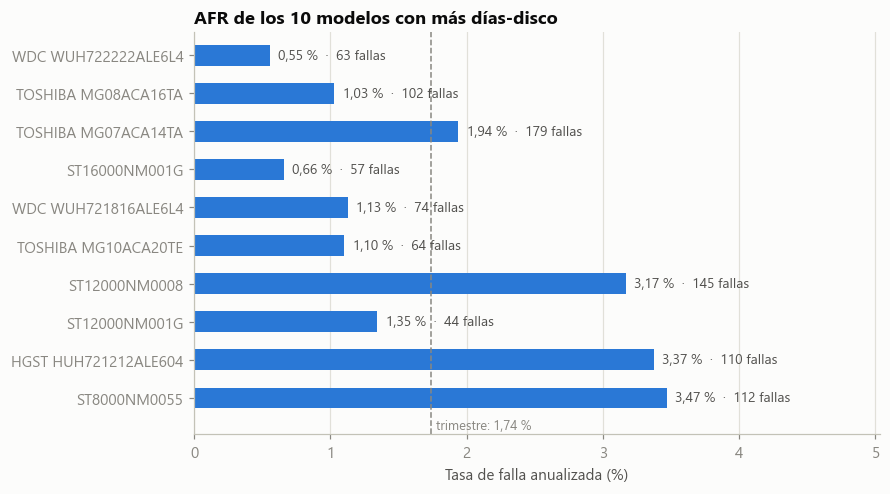

In [5]:
top = a.sort_values("dias_disco", ascending=False).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8.2, 4.6))
y = np.arange(len(top))
ax.barh(y, top["afr_pct"], height=0.55, color=AZUL)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["afr_pct"] + 0.06, yi, f"{r['afr_pct']:.2f} %".replace(".", ",") + f"  ·  {fallas_txt(r['fallas'])}",
            va="center", fontsize=9, color=TINTA2)
ax.axvline(afr_total, color=TENUE, lw=1, ls="--")
ax.set_ylim(-0.95, len(top) - 0.4)
ax.text(afr_total + 0.04, -0.9, f"trimestre: {afr_total:.2f} %".replace(".", ","), fontsize=8.5, color=TENUE, va="bottom")
ax.set_yticks(y, top["modelo"])
ax.set_xlabel("Tasa de falla anualizada (%)")
ax.set_xlim(0, top["afr_pct"].max() * 1.45)
ax.set_title("AFR de los 10 modelos con más días-disco")
solo_rejilla(ax, "x")
plt.tight_layout()
plt.show()

### Por qué hay que desconfiar de las muestras pequeñas

Cada punto es un modelo. Los que tienen pocos días-disco (izquierda) dispersan hacia valores extremos, y a medida que se acumulan datos las tasas convergen hacia el promedio. Una sola falla en un modelo pequeño dispara su AFR, y por eso la Parte D exige un mínimo de días-disco.

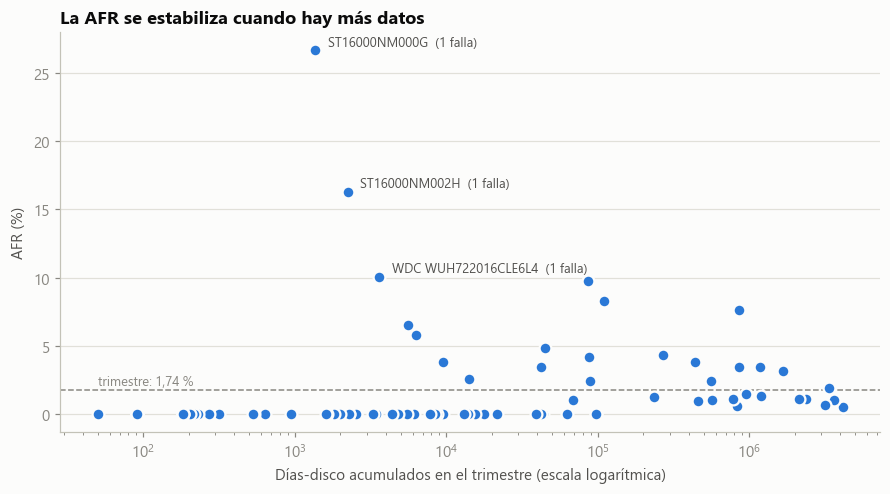

In [6]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.scatter(a["dias_disco"], a["afr_pct"], s=60, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5, zorder=3)
ax.set_xscale("log")
ax.axhline(afr_total, color=TENUE, lw=1, ls="--")
ax.text(a["dias_disco"].min(), afr_total + 0.4, f"trimestre: {afr_total:.2f} %".replace(".", ","), fontsize=8.5, color=TENUE)

for _, r in a.nlargest(3, "afr_pct").iterrows():
    ax.annotate(f"{r['modelo']}  ({fallas_txt(r['fallas'])})", (r["dias_disco"], r["afr_pct"]),
                textcoords="offset points", xytext=(8, 3), fontsize=8.5, color=TINTA2)
ax.set_xlabel("Días-disco acumulados en el trimestre (escala logarítmica)")
ax.set_ylabel("AFR (%)")
ax.set_title("La AFR se estabiliza cuando hay más datos")
solo_rejilla(ax, "y")
plt.tight_layout()
plt.show()

### Censura: cuántos discos siguen vivos

Además de los modelos, se cuentan los **días observados por serial**. Casi ningún disco falla dentro de la ventana, y de esos solo sabemos que *aún no han fallado*: es el dato censurado que motiva el análisis de supervivencia del reto.

Se calculan aquí a partir de los CSV de `data/slim`, en una sola pasada por los archivos con dos cortes: a los 14 días (la muestra de las primeras pruebas) y al final del trimestre. Comparar las dos ventanas muestra cómo cambia la censura al observar más tiempo.

In [7]:
if DATOS.exists():
    archivos = sorted(DATOS.glob("*.csv"))
    cortes = {14: "Ventana de 14 días", len(archivos): f"Trimestre ({len(archivos)} días)"}
    acum, columnas = None, {}
    for i, f in enumerate(archivos, start=1):
        d = pd.read_csv(f, usecols=["serial_number", "failure"])
        g = d.groupby("serial_number")["failure"].agg(dias="size", fallo="max")
        acum = g if acum is None else acum.add(g, fill_value=0)      # días observados y si falló, por serial
        if i in cortes:
            distintos = len(acum)
            fallaron = int((acum["fallo"] > 0).sum())
            columnas[cortes[i]] = {
                "Discos distintos": distintos,
                "Observados todos los días": int((acum["dias"] == i).sum()),
                "Fallaron en la ventana": fallaron,
                "Censurados (siguen vivos)": distintos - fallaron,
            }
    censura = pd.DataFrame(columnas)
    resumen_censura = censura.map(miles)
    resumen_censura.loc["% censurados"] = [
        f"{100 * censura.loc['Censurados (siguen vivos)', c] / censura.loc['Discos distintos', c]:.2f} %".replace(".", ",")
        for c in censura.columns]
    display(resumen_censura)
else:
    print("data/slim no está disponible; la tabla de censura se calcula con esos archivos.")

,Ventana de 14 días,Trimestre (91 días)
Discos distintos,348.619,359.101
Observados todos los días,342.695,325.689
Fallaron en la ventana,259,1.522
Censurados (siguen vivos),348.360,357.579
% censurados,"99,93 %","99,58 %"


---
## Parte B. Balanceo de carga

Se mide el tiempo de la agregación de la Parte A con **2, 8, 32 y 200 particiones**, con dos formas de repartir los datos, y cada medición se repite 5 veces (más una corrida de calentamiento que se descarta):

- **`sin_clave`**: `repartition(k)`, reparto parejo sin mirar el contenido.
- **`por_modelo`**: `partitionBy(k)`, todas las filas de un modelo caen en la misma partición.

```python
# src/parte_b_balanceo.py (fragmento)
def ejecutar(k, modo):
    t0 = time.time()
    base = pares.repartition(k) if modo == "sin_clave" else pares.partitionBy(k)
    n_modelos = base.reduceByKey(sumar).count()
    return time.time() - t0, n_modelos

# Sesgo: filas por partición con y sin clave
cuentas = (df.repartition(k, "model")                       # por modelo (sin clave: df.repartition(k))
             .withColumn("particion", F.spark_partition_id())
             .groupBy("particion").count().collect())
```

Las pruebas usan los **primeros 14 días** (4.848.207 filas) en un cluster de **4 cores**.

### Tiempos

In [8]:
t = pd.read_csv(RESULTADOS / "parte_b_tiempos.csv")
res = (t.groupby(["particiones", "reparto"])["segundos"]
         .agg(media="mean", desv=lambda s: s.std(ddof=0), mín="min", máx="max", n="count").reset_index())

def coma(x):
    return f"{x:.2f}".replace(".", ",")

tabla = res.pivot(index="particiones", columns="reparto", values="media").map(coma)
desv = res.pivot(index="particiones", columns="reparto", values="desv").map(coma)
mostrar = (tabla + " ± " + desv)[["sin_clave", "por_modelo"]].rename(columns={"sin_clave": "sin_clave (s)", "por_modelo": "por_modelo (s)"})
mostrar.index.name = "particiones"
print(f"Tiempo medio ± desviación, {int(res['n'].iloc[0])} repeticiones")
display(mostrar)

Tiempo medio ± desviación, 5 repeticiones


reparto,sin_clave (s),por_modelo (s)
particiones,,
2,"12,19 ± 0,51","15,41 ± 0,26"
8,"11,05 ± 0,52","13,36 ± 0,78"
32,"11,13 ± 0,33","13,33 ± 0,30"
200,"19,36 ± 0,88","15,85 ± 1,25"


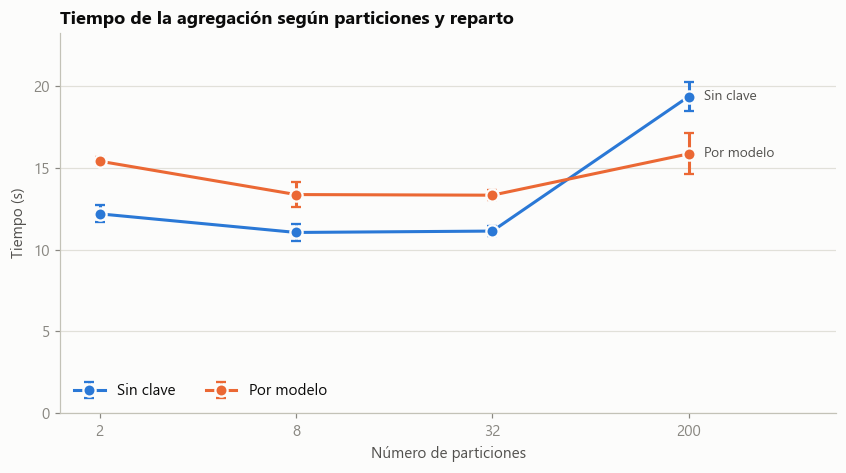

In [9]:
etiquetas = {"sin_clave": ("Sin clave", AZUL), "por_modelo": ("Por modelo", NARANJA)}
ks = sorted(res["particiones"].unique())
x = np.arange(len(ks))

fig, ax = plt.subplots(figsize=(7.8, 4.4))
for modo, (nombre, color) in etiquetas.items():
    s = res[res["reparto"] == modo].set_index("particiones").loc[ks]
    ax.errorbar(x, s["media"], yerr=s["desv"], color=color, lw=2, marker="o", ms=8, mec=SUPERFICIE, mew=1.5,
                capsize=3, label=nombre, zorder=3)
    ax.text(x[-1] + 0.08, s["media"].iloc[-1], nombre, color=TINTA2, va="center", fontsize=9)
ax.set_xticks(x, ks)
ax.set_xlim(-0.2, len(ks) - 1 + 0.75)
ax.set_xlabel("Número de particiones")
ax.set_ylabel("Tiempo (s)")
ax.set_ylim(0, res["media"].max() * 1.2)
ax.set_title("Tiempo de la agregación según particiones y reparto")
ax.legend(frameon=False, loc="lower left", ncol=2)
solo_rejilla(ax, "y")
plt.tight_layout()
plt.show()

Lectura de las mediciones:

- **Sin clave:** pasar de 2 a 8 particiones mejora un poco (de 12,2 a 11,1 s); de 8 a 32 no cambia. Con 4 cores no hay nada que ganar con más de unas 8 particiones, y con **200 el tiempo sube alrededor de un 75 %** (19,4 s frente a 11,1 s): lanzar 200 tareas pequeñas cuesta más de lo que ahorra.
- **Por modelo** es más lento que sin clave con 2, 8 y 32 particiones (entre 2 y 3 s más), pero con **200 resulta más rápido** (15,9 s contra 19,4 s). La sección de sesgo lo explica.

### Sesgo: filas por partición

In [10]:
if DATOS.exists():
    conc = pd.concat([pd.read_csv(f, usecols=["model"]) for f in sorted(DATOS.glob("*.csv"))[:14]])["model"].value_counts()
    c = pd.DataFrame({"filas": conc, "% del total": 100 * conc / conc.sum()})
    c["% acumulado"] = c["% del total"].cumsum()
    top5 = f"{c['% acumulado'].iloc[4]:.1f}".replace(".", ",")
    print(f"{len(conc)} modelos, {miles(conc.sum())} filas (14 días). Los 5 mayores concentran el {top5} % de las filas")
    mostrar = c.head(10).copy()
    mostrar["filas"] = mostrar["filas"].map(miles)
    for col in ("% del total", "% acumulado"):
        mostrar[col] = mostrar[col].map(lambda v: f"{v:.1f} %".replace(".", ","))
    display(mostrar)
else:
    print("data/slim no está disponible; la concentración por modelo se calcula con esos archivos.")

79 modelos, 4.848.207 filas (14 días). Los 5 mayores concentran el 52,9 % de las filas


,filas,% del total,% acumulado
model,,,
WDC WUH722222ALE6L4,638.253,"13,2 %","13,2 %"
TOSHIBA MG08ACA16TA,554.880,"11,4 %","24,6 %"
TOSHIBA MG07ACA14TA,519.577,"10,7 %","35,3 %"
ST16000NM001G,484.653,"10,0 %","45,3 %"
WDC WUH721816ALE6L4,367.608,"7,6 %","52,9 %"
TOSHIBA MG10ACA20TE,292.336,"6,0 %","58,9 %"
ST12000NM0008,258.309,"5,3 %","64,3 %"
ST12000NM001G,184.057,"3,8 %","68,1 %"
HGST HUH721212ALE604,183.704,"3,8 %","71,8 %"


In [11]:
p = pd.read_csv(RESULTADOS / "parte_b_particiones.csv")
sesgo = (p.groupby(["particiones", "reparto"])["filas"]
           .agg(mín="min", máx="max", media="mean", vacías=lambda s: int((s == 0).sum()), total="count").reset_index())
sesgo["máx/media"] = sesgo["máx"] / sesgo["media"]

vista = sesgo.copy()
for col in ("mín", "máx", "media"):
    vista[col] = vista[col].map(miles)
vista["máx/media"] = vista["máx/media"].map(lambda v: f"{v:.2f}".replace(".", ","))
vista["vacías"] = vista["vacías"].astype(str) + " de " + vista["total"].astype(str)
display(vista.drop(columns="total").set_index(["particiones", "reparto"]))

mín        máx      media      vacías máx/media
particiones reparto                                                          
2           por_modelo  2.417.930  2.430.277  2.424.104      0 de 2      1,00
            sin_clave   2.424.103  2.424.104  2.424.104      0 de 2      1,00
8           por_modelo     18.807  1.111.727    606.026      0 de 8      1,83
            sin_clave     606.025    606.027    606.026      0 de 8      1,00
32          por_modelo          0    737.077    151.506     3 de 32      4,86
            sin_clave     151.505    151.508    151.506     0 de 32      1,00
200         por_modelo          0    638.253     24.241  131 de 200     26,33
            sin_clave      24.239     24.243     24.241    0 de 200      1,00

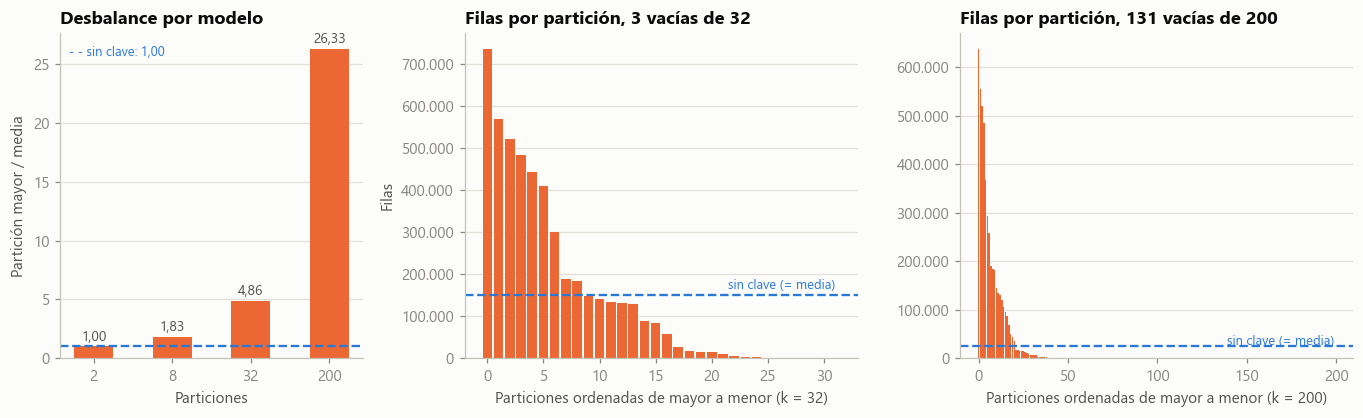

In [12]:
pm = sesgo[sesgo["reparto"] == "por_modelo"].set_index("particiones")

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1.0, 1.3, 1.3]})

# (1) cuánto pesa la partición más cargada respecto a la media
ax = axs[0]
x = np.arange(len(pm))
ax.bar(x, pm["máx/media"], width=0.5, color=NARANJA)
for xi, v in zip(x, pm["máx/media"]):
    ax.text(xi, v + 0.5, f"{v:.2f}".replace(".", ","), ha="center", fontsize=9, color=TINTA2)
ax.axhline(1, color=AZUL, lw=1.5, ls="--")
ax.text(0.03, 0.96, "- - sin clave: 1,00", color=AZUL, fontsize=8.5, ha="left", va="top", transform=ax.transAxes)
ax.set_xticks(x, pm.index)
ax.set_xlabel("Particiones")
ax.set_ylabel("Partición mayor / media")
ax.set_title("Desbalance por modelo")
solo_rejilla(ax, "y")

# (2) y (3) tamaño de cada partición, ordenado, para 32 y 200 particiones
for ax, k in zip(axs[1:], (32, 200)):
    v = p[(p["particiones"] == k) & (p["reparto"] == "por_modelo")]["filas"].sort_values(ascending=False).to_numpy()
    ax.bar(np.arange(k), v, width=0.85, color=NARANJA)
    ax.axhline(v.mean(), color=AZUL, lw=1.5, ls="--")
    ax.text(k - 1, v.mean() * 1.08, "sin clave (= media)", color=AZUL, fontsize=8.5, ha="right")
    ax.set_xlabel(f"Particiones ordenadas de mayor a menor (k = {k})")
    ax.set_title(f"Filas por partición, {int((v == 0).sum())} vacías de {k}")
    ax.yaxis.set_major_formatter(lambda val, _: miles(val))
    solo_rejilla(ax, "y")
axs[1].set_ylabel("Filas")
plt.tight_layout()
plt.show()

Lo que muestran los conteos de filas por partición:

- **Sin clave el reparto es casi perfecto** (partición mayor / media = 1,00 con cualquier número de particiones). El sesgo viene de la clave, no de los datos.
- **Por modelo el sesgo crece con el número de particiones:** 1,00 con 2, 1,83 con 8, 4,86 con 32 y **26,33 con 200**. La concentración de los datos (los 5 mayores modelos tienen el 52,9 % de las filas) hace que unas pocas particiones carguen con casi todo.
- **Con 200 particiones, 131 quedan vacías** y la mayor tiene 638.253 filas: exactamente el tamaño del modelo más grande (`WDC WUH722222ALE6L4`). Con 79 modelos, a lo sumo 79 particiones pueden tener datos, y esa partición no se puede dividir más sin cambiar la clave.
- **Eso explica la anomalía de los tiempos:** con 200 particiones el reparto por modelo, aunque muy desbalanceado, lanza solo unas 69 tareas con trabajo y 131 vacías casi gratis, mientras que el reparto sin clave lanza 200 tareas reales. La relación entre sesgo y tiempo no es lineal: cuenta cuánto trabajo tiene la tarea más cargada y cuántas tareas hay que lanzar.

Estas conclusiones valen para estos datos y este cluster de 4 cores; no son una regla general.

---
## Parte C. Streaming con Kafka

Un *producer* en Python lee los CSV día por día y publica cada fila como JSON en el tema `discos` de Kafka, con un reloj acelerado de **un día cada 10 segundos**. Para que el producer aguante (unas 350 mil filas diarias en total) se filtran **3 modelos** con volumen y fallas suficientes en la Parte A: `TOSHIBA MG07ACA14TA`, `ST12000NM0008` y `ST8000NM0055`.

Structured Streaming lee el tema, agrupa por modelo en **ventanas de 7 días** (el tiempo del evento es la fecha de la fila) con **watermark de 2 días**, y calcula días-disco, fallas y AFR por ventana.

```python
# src/parte_c_producer.py (fragmento)
for archivo in archivos:                                     # un día de datos...
    for fila in csv.DictReader(f):
        if fila["model"] in modelos:
            productor.send("discos", key=fila["serial_number"], value=fila)
    productor.flush()
    time.sleep(args.segundos_por_dia - gastado)              # ...cada 10 s

# src/parte_c_streaming.py (fragmento)
eventos = (spark.readStream.format("kafka")
           .option("kafka.bootstrap.servers", "kafka:19092").option("subscribe", "discos")
           .option("startingOffsets", "earliest").load()
           .select(F.from_json(F.col("value").cast("string"), ESQUEMA).alias("e")).select("e.*")
           .withColumn("fecha", F.to_timestamp("date")))

ventanas = (eventos.withWatermark("fecha", "2 days")
            .groupBy(F.window("fecha", "7 days"), F.col("model").alias("modelo"))
            .agg(F.count("*").alias("dias_disco"), F.sum("failure").alias("fallas")))
```

### El producer alcanzó el ritmo

In [13]:
log = (RESULTADOS / "parte_c_producer.log").read_text(encoding="utf-8", errors="replace")
dias_log = re.findall(r"(\d{4}-\d{2}-\d{2}): (\d+) filas enviadas en ([\d.]+) s", log)
envio = pd.DataFrame(dias_log, columns=["fecha", "filas", "segundos"]).astype({"filas": int, "segundos": float})
print(f"{len(envio)} días enviados, {miles(envio['filas'].sum())} mensajes")
print(f"Tiempo por día: media {envio['segundos'].mean():.1f} s, máximo {envio['segundos'].max():.1f} s (el reloj marcaba 10 s por día)".replace(".", ","))
print("¿Algún día superó los 10 s?", bool((envio["segundos"] > 10).any()))

14 días enviados, 960.203 mensajes
Tiempo por día: media 8,1 s, máximo 9,9 s (el reloj marcaba 10 s por día)
¿Algún día superó los 10 s? False


### Resultado: AFR por ventana

Las ventanas de 7 días las alinea Spark a su propia época (empiezan en jueves). Como los datos van del 1 al 14 de abril, **la primera ventana solo tiene 1 día y la última 6**; en el gráfico se marcan con un punto hueco porque su AFR cubre menos tiempo.

In [14]:
v = pd.read_csv(RESULTADOS / "parte_c_ventanas.csv", parse_dates=["inicio", "fin"])
v["afr_pct"] = afr(v["fallas"], v["dias_disco"])

# días realmente enviados dentro de cada ventana
enviados = pd.to_datetime(envio["fecha"])
v["dias_en_ventana"] = [int(((enviados >= i) & (enviados < f)).sum()) for i, f in zip(v["inicio"], v["fin"])]

MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
def rotulo(i, f):
    f = f - pd.Timedelta(days=1)
    return f"{i.day} {MESES[i.month - 1]} – {f.day} {MESES[f.month - 1]}"

v["ventana"] = [rotulo(i, f) for i, f in zip(v["inicio"], v["fin"])]
vista = v[["ventana", "modelo", "dias_en_ventana", "dias_disco", "fallas", "afr_pct"]].copy()
vista["dias_disco"] = vista["dias_disco"].map(miles)
vista["afr_pct"] = vista["afr_pct"].map(lambda x: f"{x:.2f}".replace(".", ","))
display(vista.set_index(["ventana", "modelo"]))

dias_en_ventana dias_disco  fallas afr_pct
ventana        modelo                                                         
26 mar – 1 abr ST12000NM0008                      1     18.461       1    1,98
               ST8000NM0055                       1     13.045       0    0,00
               TOSHIBA MG07ACA14TA                1     37.152       2    1,96
2 abr – 8 abr  ST12000NM0008                      7    129.171       9    2,54
               ST8000NM0055                       7     91.310       8    3,20
               TOSHIBA MG07ACA14TA                7    259.797      21    2,95
9 abr – 15 abr ST12000NM0008                      6    110.677      13    4,29
               ST8000NM0055                       6     77.962      17    7,96
               TOSHIBA MG07ACA14TA                6    222.628       6    0,98

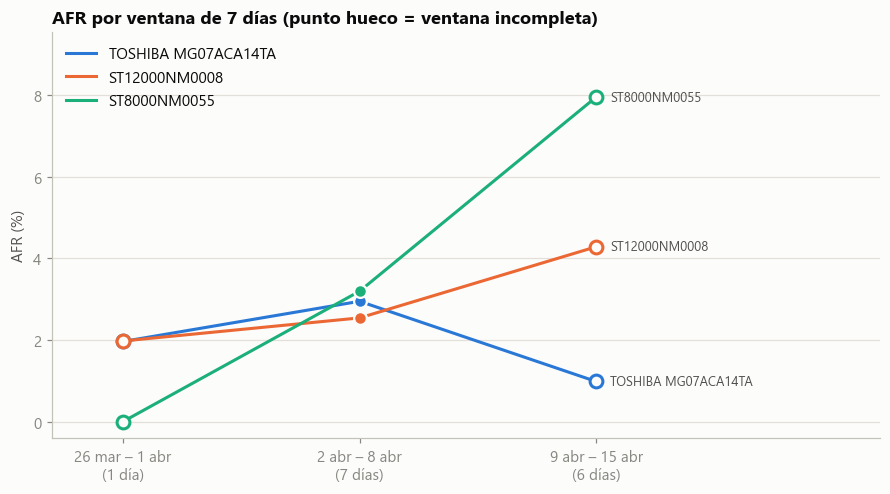

In [15]:
modelos = ["TOSHIBA MG07ACA14TA", "ST12000NM0008", "ST8000NM0055"]
colores = dict(zip(modelos, [AZUL, NARANJA, AQUA]))
ventanas = list(dict.fromkeys(v["ventana"]))
x = np.arange(len(ventanas))

fig, ax = plt.subplots(figsize=(8.2, 4.6))
for m in modelos:
    s = v[v["modelo"] == m].set_index("ventana").loc[ventanas]
    ax.plot(x, s["afr_pct"], color=colores[m], lw=2, label=m, zorder=2)
    completa = (s["dias_en_ventana"] == 7).to_numpy()
    ax.scatter(x[completa], s["afr_pct"][completa], s=70, color=colores[m], edgecolor=SUPERFICIE, linewidth=1.5, zorder=3)
    ax.scatter(x[~completa], s["afr_pct"][~completa], s=70, facecolor=SUPERFICIE, edgecolor=colores[m], linewidth=2, zorder=3)
    ax.text(x[-1] + 0.06, s["afr_pct"].iloc[-1], m, color=TINTA2, va="center", fontsize=8.5)

dias_v = v.drop_duplicates("ventana").set_index("ventana").loc[ventanas, "dias_en_ventana"]
ax.set_xticks(x, [f"{w}\n({d} día{'s' if d != 1 else ''})" for w, d in zip(ventanas, dias_v)])
ax.set_xlim(-0.3, len(x) - 1 + 1.2)
ax.set_ylabel("AFR (%)")
ax.set_ylim(-0.4, v["afr_pct"].max() * 1.2)
ax.set_title("AFR por ventana de 7 días (punto hueco = ventana incompleta)")
ax.legend(frameon=False, loc="upper left")
solo_rejilla(ax, "y")
plt.tight_layout()
plt.show()

Dos precauciones al leer estas cifras:

- **La AFR en ventanas cortas es muy volátil.** `ST8000NM0055` pasa de 3,20 % a 7,96 % entre dos ventanas consecutivas con solo 77.962 días-disco: una falla más o menos mueve mucho la tasa. Es la misma advertencia de la Parte A.
- **Los lotes intermedios muestran valores parciales** que se corrigen en los siguientes (modo `update`): la ventana más reciente se actualiza en cada lote a medida que llegan los días.
- **El watermark está configurado, pero esta corrida no lo pone a prueba.** El producer envía los días en orden y sin datos tardíos, así que no se muestra qué filas descarta el watermark de 2 días.

### Verificación contra los datos originales

Se recalculan las ventanas directamente desde los CSV, sin Spark ni Kafka, y se comparan con lo que produjo el streaming.

In [16]:
if DATOS.exists():
    ndias = len(envio)
    partes = [pd.read_csv(f, usecols=["date", "model", "failure"]) for f in sorted(DATOS.glob("*.csv"))[:ndias]]
    d = pd.concat(partes)
    d = d[d["model"].isin(modelos)].copy()
    dias_epoca = (pd.to_datetime(d["date"]) - pd.Timestamp("1970-01-01")).dt.days   # Spark alinea ventanas a la época
    d["inicio"] = pd.Timestamp("1970-01-01") + pd.to_timedelta(dias_epoca // 7 * 7, unit="D")
    real = d.groupby(["inicio", "model"]).agg(dias_disco=("failure", "size"), fallas=("failure", "sum")).reset_index()
    cmp_ = v.merge(real, left_on=["inicio", "modelo"], right_on=["inicio", "model"], suffixes=("_spark", "_csv"))
    ok = (cmp_["dias_disco_spark"] == cmp_["dias_disco_csv"]) & (cmp_["fallas_spark"] == cmp_["fallas_csv"])
    print(f"{int(ok.sum())} de {len(v)} ventanas por modelo coinciden exactamente con el cálculo directo desde los CSV")
else:
    print("data/slim no está disponible; la verificación se hace contra esos archivos.")

9 de 9 ventanas por modelo coinciden exactamente con el cálculo directo desde los CSV


---
## Parte D. MongoDB

Se guardan los agregados por modelo y ventana en MongoDB y se consultan los **5 modelos con mayor tasa de falla que tengan un mínimo de días-disco**, para no sacar conclusiones de muestras pequeñas.

Como el streaming solo cubre 3 modelos, los agregados del trimestre se calculan con Spark (`src/parte_d_agregados.py`): las mismas ventanas de 7 días, con los 81 modelos y los 91 días, **1.121 documentos**. La salida del streaming se guarda aparte, en `ventanas_streaming`.

```python
# src/parte_d_mongo.py (fragmento): top 5 por AFR con un mínimo de días-disco
pipeline = [
    {"$group": {"_id": "$modelo", "dias_disco": {"$sum": "$dias_disco"}, "fallas": {"$sum": "$fallas"}}},
    {"$match": {"dias_disco": {"$gte": minimo}}},                     # descarta las muestras pequeñas
    {"$project": {"dias_disco": 1, "fallas": 1,
                  "afr_pct": {"$multiply": [{"$divide": ["$fallas", {"$divide": ["$dias_disco", 365]}]}, 100]}}},
    {"$sort": {"afr_pct": -1}},
    {"$limit": 5},
]
list(db["ventanas"].aggregate(pipeline))
```

Para que el notebook funcione sin MongoDB encendido, las consultas se reproducen aquí con pandas sobre el mismo CSV que se cargó (`parte_d_ventanas.csv`). Más abajo hay una celda opcional que consulta el MongoDB real.

In [17]:
w = pd.read_csv(RESULTADOS / "parte_d_ventanas.csv")
print(f"{miles(len(w))} documentos (modelo, ventana)")

MINIMO = 100_000   # días-disco mínimos para el trimestre

tri = w.groupby("modelo").agg(dias_disco=("dias_disco", "sum"), fallas=("fallas", "sum")).reset_index()
tri["afr_pct"] = afr(tri["fallas"], tri["dias_disco"])
afr_ctrl = f"{afr(tri['fallas'].sum(), tri['dias_disco'].sum()):.2f}".replace(".", ",")
print(f"Control: {miles(tri['dias_disco'].sum())} días-disco, {miles(tri['fallas'].sum())} fallas, AFR {afr_ctrl} % (igual que la Parte A)")

sin_min = tri.nlargest(5, "afr_pct")
con_min = tri[tri["dias_disco"] >= MINIMO].nlargest(5, "afr_pct")

1.121 documentos (modelo, ventana)
Control: 31.968.003 días-disco, 1.522 fallas, AFR 1,74 % (igual que la Parte A)


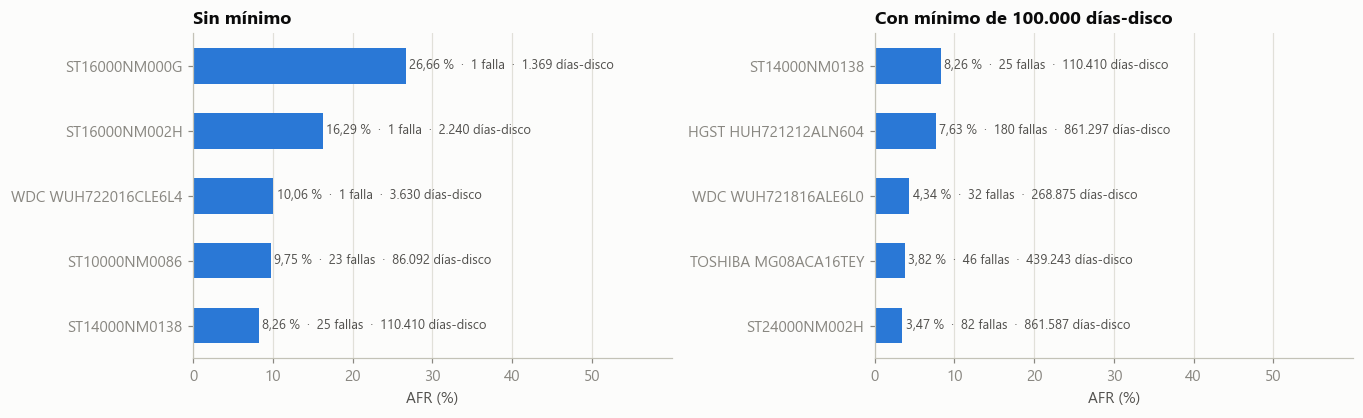

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.9), sharex=True)
for ax, datos, titulo in ((axs[0], sin_min, "Sin mínimo"), (axs[1], con_min, f"Con mínimo de {miles(MINIMO)} días-disco")):
    d = datos.iloc[::-1]
    y = np.arange(len(d))
    ax.barh(y, d["afr_pct"], height=0.55, color=AZUL)
    for yi, (_, r) in zip(y, d.iterrows()):
        etiqueta = f"{r['afr_pct']:.2f} %".replace(".", ",") + f"  ·  {fallas_txt(r['fallas'])}  ·  {miles(r['dias_disco'])} días-disco"
        ax.text(r["afr_pct"] + 0.4, yi, etiqueta, va="center", fontsize=8.5, color=TINTA2)
    ax.set_yticks(y, d["modelo"])
    ax.set_title(titulo)
    ax.set_xlabel("AFR (%)")
    solo_rejilla(ax, "x")
axs[0].set_xlim(0, sin_min["afr_pct"].max() * 2.25)
plt.tight_layout()
plt.show()

Sin mínimo, el ranking lo copian modelos con **una sola falla** y muy pocos días-disco (por ejemplo 26,66 % con 1 falla en 1.369 días-disco). Con el mínimo, el ranking se apoya en decenas o cientos de fallas.

**El umbral es una decisión, y cambia el resultado.** `ST10000NM0086` tiene 86.092 días-disco y 23 fallas (9,75 % de AFR) y queda fuera con 100.000 por poco. No hay un valor "correcto"; lo importante es declarar cuál se usó. Se puede probar otro con la variable `MINIMO` de la celda anterior.

In [19]:
# Opcional: la misma consulta contra el MongoDB real (requiere docker compose up y pymongo)
try:
    from pymongo import MongoClient
    col = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=2000)["discos"]["ventanas"]
    pipeline = [
        {"$group": {"_id": "$modelo", "dias_disco": {"$sum": "$dias_disco"}, "fallas": {"$sum": "$fallas"}}},
        {"$match": {"dias_disco": {"$gte": MINIMO}}},
        {"$project": {"dias_disco": 1, "fallas": 1,
                      "afr_pct": {"$multiply": [{"$divide": ["$fallas", {"$divide": ["$dias_disco", 365]}]}, 100]}}},
        {"$sort": {"afr_pct": -1}}, {"$limit": 5},
    ]
    mongo = pd.DataFrame(list(col.aggregate(pipeline))).rename(columns={"_id": "modelo"})
    display(mongo)
    print("Coincide con pandas:", mongo["modelo"].tolist() == con_min["modelo"].tolist())
except Exception as e:
    print("MongoDB no disponible, se omite esta celda:", type(e).__name__)

,modelo,dias_disco,fallas,afr_pct
0,ST14000NM0138,110410,25,8.264650
1,HGST HUH721212ALN604,861297,180,7.628031
2,WDC WUH721816ALE6L0,268875,32,4.344026
3,TOSHIBA MG08ACA16TEY,439243,46,3.822486
4,ST24000NM002H,861587,82,3.473822


Coincide con pandas: True


---
## Criterios de evaluación: dónde se cumple cada uno

| Criterio del enunciado | Dónde se ve | Estado |
|---|---|---|
| Días-disco y fallas por modelo coinciden con un `groupBy` de DataFrames | Parte A: celda de verificación (pandas) y salida del script (Spark) | Cumplido en los 81 modelos |
| Tasa anualizada con la fórmula correcta | Parte A: `afr()`, y total del trimestre contra Backblaze | Cumplido; da 1,74 % frente a 1,73 %, no exactamente igual |
| Interpretación cuidadosa con pocos datos | Parte A (gráfico de dispersión) y Parte D (top 5 con y sin mínimo) | Cumplido |
| Tabla de tiempos con mediciones propias y repetidas | Parte B: 4 particiones x 2 repartos x 5 repeticiones | Cumplido |
| Sesgo explicado con filas por partición | Parte B: conteos con `spark_partition_id()` en las 4 configuraciones | Cumplido |
| Flujo con ventanas y watermark de punta a punta sobre Kafka | Parte C: producer, Kafka, Structured Streaming y verificación contra los CSV | Cumplido; el watermark está activo pero no se probó con datos tardíos |
| Reto de investigación con evidencia propia | Sección siguiente: Spark resume los discos, Python estima las curvas | Cumplido; el tiempo es de observación en el trimestre, no la edad del disco |

Dos límites que conviene declarar: las diferencias con las cifras de Backblaze (31.968.003 contra 31.553.350 días-disco, y 1.522 contra 1.498 fallas) no se explicaron con una comprobación, y las pruebas de tiempos se hicieron en un cluster local de 4 cores.

---
## Reto de investigación: Kaplan-Meier

**La pregunta:** ¿qué probabilidad tiene un disco de seguir vivo después de *t* días, y cambia según el modelo?

**El problema:** el 99,58 % de los discos sigue vivo al final del trimestre (censura, Parte A). Promediar el tiempo de los que fallaron sesgaría todo hacia valores cortos. Kaplan-Meier está hecho para esto: en cada instante *t<sub>i</sub>* en que falla algún disco, la supervivencia se multiplica por la fracción que sobrevivió,

$$\hat S(t) = \prod_{t_i \le t} \left(1 - \frac{d_i}{n_i}\right)$$

donde *d<sub>i</sub>* son las fallas en *t<sub>i</sub>* y *n<sub>i</sub>* los discos **todavía en observación** justo antes de *t<sub>i</sub>*. Un disco censurado cuenta en *n<sub>i</sub>* mientras se le observa y sale de ahí cuando deja de observarse, pero **nunca cuenta como falla**. Así se aprovecha la información de los discos que siguen vivos sin inventar su final.

**La integración con lo anterior:** Spark resume el trimestre por disco (`src/reto_km_agregados.py`) y el resultado pasa a Python, donde `lifelines` estima las curvas.

```python
# src/reto_km_agregados.py (fragmento): un registro por disco con todo el trimestre
por_disco = (spark.read.csv(rutas, header=True)
             .groupBy("serial_number")
             .agg(F.first("model").alias("modelo"),
                  F.min("date").alias("primer_dia"),            # cuándo empieza a observarse
                  F.max("date").alias("ultimo_dia"),            # cuándo deja de observarse
                  F.count("*").alias("dias_registrados"),
                  F.max(F.col("failure").cast("int")).alias("fallo")))   # 1 = falló (evento), 0 = censurado
```

**Cómo se define el tiempo.** `duracion` = días de calendario entre el primer y el último registro del disco (contando ambos), y `evento` = 1 si ese último registro marca una falla. **El origen del tiempo es el primer día en que vemos al disco dentro del trimestre, no su fecha de instalación**, que el dataset no trae. Esto se discute al final.

### Los datos por disco

In [20]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test


def pct(x, dec=2):
    return f"{100 * x:.{dec}f} %".replace(".", ",")


vida = pd.read_csv(RESULTADOS / "km_vida_por_disco.csv", parse_dates=["primer_dia", "ultimo_dia"])
vida["duracion"] = (vida["ultimo_dia"] - vida["primer_dia"]).dt.days + 1   # días de observación (calendario)
vida["evento"] = vida["fallo"]                                              # 1 = falló, 0 = censurado

print(f"{miles(len(vida))} discos, {miles(vida['evento'].sum())} fallas, {vida['modelo'].nunique()} modelos")
print(f"Discos cuyo primer y último registro están a {vida['duracion'].max()} días (todo el trimestre): {pct((vida['duracion'] == vida['duracion'].max()).mean())}")
print("(la tabla de censura de la Parte A cuenta filas, no días de calendario, por eso da un porcentaje menor)")
print(f"Discos con días sin registro entre su primer y último día: {pct((vida['duracion'] != vida['dias_registrados']).mean())}")
display(vida.head(3))

359.101 discos, 1.522 fallas, 81 modelos
Discos cuyo primer y último registro están a 91 días (todo el trimestre): 95,34 %
(la tabla de censura de la Parte A cuenta filas, no días de calendario, por eso da un porcentaje menor)
Discos con días sin registro entre su primer y último día: 5,47 %


,serial_number,modelo,primer_dia,ultimo_dia,dias_registrados,fallo,duracion,evento
0,1040A04SF9RG,TOSHIBA MG07ACA14TEY,2026-04-01,2026-06-30,91,0,91,0
1,1040A087F97G,TOSHIBA MG07ACA14TA,2026-04-01,2026-06-30,91,0,91,0
2,1060A029F97G,TOSHIBA MG07ACA14TA,2026-04-01,2026-06-30,91,0,91,0


### Qué pasa si se ignora la censura

Si solo se mirara el tiempo de los discos que fallaron, la conclusión sería que "los discos duran unas pocas semanas". Kaplan-Meier cuenta otra historia, porque tiene en cuenta a los que siguen vivos.

In [21]:
fallaron = vida[vida["evento"] == 1]
km_total = KaplanMeierFitter().fit(vida["duracion"], vida["evento"])
s91_total = float(km_total.predict(91))

print(f"Discos que fallaron: media de {fallaron['duracion'].mean():.1f} días observados (mediana {fallaron['duracion'].median():.0f})".replace(".", ","))
print(f"Kaplan-Meier, todos los discos: probabilidad de seguir vivo a los 91 días = {pct(s91_total)}")
print(f"(solo {pct(1 - s91_total)} de los discos observados falla en esos 91 días)")

Discos que fallaron: media de 37,8 días observados (mediana 33)
Kaplan-Meier, todos los discos: probabilidad de seguir vivo a los 91 días = 99,57 %
(solo 0,43 % de los discos observados falla en esos 91 días)


### Kaplan-Meier a mano y con `lifelines`

Para comprobar que se entiende el método, se implementa la fórmula directamente (arriba) y se compara con `lifelines`. Las dos curvas deben coincidir.

```python
def kaplan_meier_manual(duracion, evento):
    tiempos = np.sort(np.unique(duracion[evento == 1]))            # instantes con al menos una falla
    S, curva = 1.0, {}
    for t in tiempos:
        n_riesgo = (duracion >= t).sum()                            # aún en observación justo antes de t
        fallas_t = ((duracion == t) & (evento == 1)).sum()
        S *= 1 - fallas_t / n_riesgo                                # los censurados solo reducen n_riesgo
        curva[t] = S
    return pd.Series(curva)
```

In [22]:
def kaplan_meier_manual(duracion, evento):
    duracion, evento = np.asarray(duracion), np.asarray(evento)
    tiempos = np.sort(np.unique(duracion[evento == 1]))
    S, curva = 1.0, {}
    for t in tiempos:
        n_riesgo = (duracion >= t).sum()
        fallas_t = ((duracion == t) & (evento == 1)).sum()
        S *= 1 - fallas_t / n_riesgo
        curva[t] = S
    return pd.Series(curva)


# Cuatro modelos con tasas de falla muy distintas (Parte A): alta, media-alta, media y baja
modelos_km = ["ST8000NM0055", "ST12000NM0008", "TOSHIBA MG07ACA14TA", "WDC WUH722222ALE6L4"]
colores_km = dict(zip(modelos_km, [AZUL, NARANJA, AQUA, "#eda100"]))

filas = []
for m in modelos_km:
    s = vida[vida["modelo"] == m]
    manual = kaplan_meier_manual(s["duracion"], s["evento"])
    lf = KaplanMeierFitter().fit(s["duracion"], s["evento"]).survival_function_.iloc[:, 0]
    dif = np.abs(lf.reindex(manual.index).to_numpy() - manual.to_numpy()).max()
    filas.append((m, miles(len(s)), len(manual), f"{dif:.1e}".replace(".", ",")))
display(pd.DataFrame(filas, columns=["modelo", "discos", "instantes con fallas", "diferencia máxima con lifelines"]).set_index("modelo"))

,discos,instantes con fallas,diferencia máxima con lifelines
modelo,,,
ST8000NM0055,13.112,52,"2,0e-15"
ST12000NM0008,18.521,72,"4,0e-15"
TOSHIBA MG07ACA14TA,37.171,73,"4,2e-15"
WDC WUH722222ALE6L4,45.665,41,"5,0e-15"


### Curvas de supervivencia por modelo

La línea es la probabilidad estimada de seguir vivo tras *t* días de observación, y la banda es el intervalo de confianza del 95 %. **El eje vertical empieza en 98,8 %, no en 0**: con tan pocas fallas las curvas se quedan muy cerca de 100 %, y desde cero no se distinguirían.

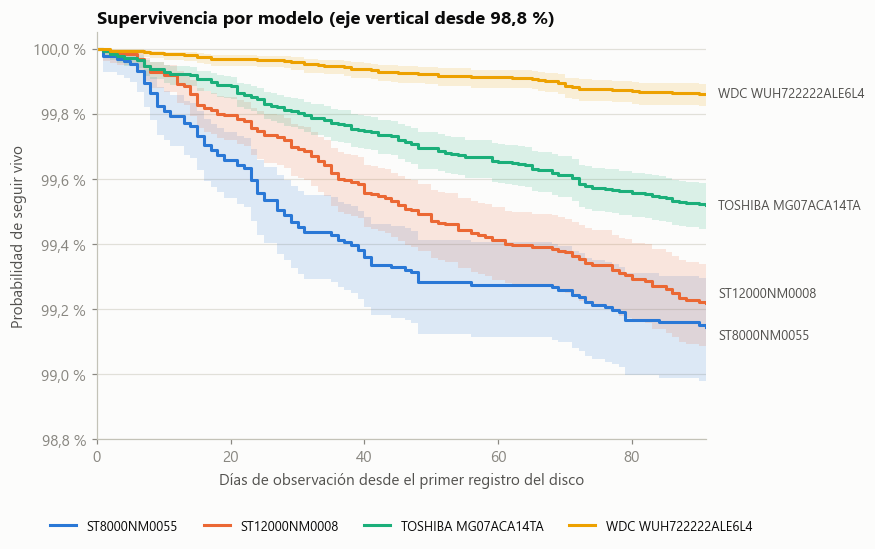

In [23]:
DESPLAZAMIENTO = {"ST8000NM0055": -6, "ST12000NM0008": 6}      # separa etiquetas que quedarían superpuestas

fig, ax = plt.subplots(figsize=(9, 4.8))
for m in modelos_km:
    s = vida[vida["modelo"] == m]
    kmf = KaplanMeierFitter().fit(s["duracion"], s["evento"], label=m)
    sf, ci = kmf.survival_function_[m], kmf.confidence_interval_
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step="post", color=colores_km[m], alpha=0.15, linewidth=0)
    ax.step(sf.index, sf.values, where="post", color=colores_km[m], lw=2, label=m)
    ax.annotate(m, xy=(sf.index.max(), sf.iloc[-1]), xytext=(8, DESPLAZAMIENTO.get(m, 0)), textcoords="offset points",
                fontsize=8.5, color=TINTA2, va="center", annotation_clip=False)

ax.set_xlim(0, vida["duracion"].max())
ax.set_ylim(0.988, 1.0005)
ax.yaxis.set_major_formatter(lambda v, _: f"{100 * v:.1f} %".replace(".", ","))
ax.set_xlabel("Días de observación desde el primer registro del disco")
ax.set_ylabel("Probabilidad de seguir vivo")
ax.set_title("Supervivencia por modelo (eje vertical desde 98,8 %)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=8.5)
solo_rejilla(ax, "y")
fig.subplots_adjust(right=0.74)
plt.show()

### Kaplan-Meier frente a la AFR

Con una tasa de falla baja y estable, la probabilidad de fallar en 91 días debería ser casi `AFR x 91 / 365`. Se comparan las dos estimaciones para los modelos con al menos 50 fallas (donde las cifras son más fiables), con el intervalo de confianza que la AFR no da.

In [24]:
filas = []
for m, g in vida.groupby("modelo"):
    fallas_m = int(g["evento"].sum())
    if fallas_m < 50:
        continue
    kmf = KaplanMeierFitter().fit(g["duracion"], g["evento"])
    s91 = float(kmf.predict(91))
    ic = kmf.confidence_interval_.loc[:91].iloc[-1]
    afr_m = afr(fallas_m, g["dias_registrados"].sum())
    filas.append({"modelo": m, "discos": len(g), "fallas": fallas_m,
                  "falla a 91 días (KM)": 1 - s91, "IC 95 %": f"{pct(1 - ic.iloc[1], 2)} a {pct(1 - ic.iloc[0], 2)}",
                  "AFR x 91/365": afr_m / 100 * 91 / 365})
tabla_km = pd.DataFrame(filas).sort_values("falla a 91 días (KM)", ascending=False).set_index("modelo")
vista = tabla_km.copy()
vista["discos"] = vista["discos"].map(miles)
vista["falla a 91 días (KM)"] = vista["falla a 91 días (KM)"].map(pct)
vista["AFR x 91/365"] = vista["AFR x 91/365"].map(pct)
display(vista)

,discos,fallas,falla a 91 días (KM),IC 95 %,AFR x 91/365
modelo,,,,,
HGST HUH721212ALN604,9.694,180,"1,86 %","1,61 % a 2,15 %","1,90 %"
ST24000NM002H,9.631,82,"0,86 %","0,69 % a 1,07 %","0,87 %"
ST8000NM0055,13.112,112,"0,86 %","0,71 % a 1,03 %","0,87 %"
HGST HUH721212ALE604,13.196,110,"0,83 %","0,69 % a 1,00 %","0,84 %"
ST12000NM0008,18.521,145,"0,78 %","0,67 % a 0,92 %","0,79 %"
TOSHIBA MG07ACA14TA,37.171,179,"0,48 %","0,42 % a 0,56 %","0,48 %"
WDC WUH721816ALE6L4,26.286,74,"0,28 %","0,22 % a 0,35 %","0,28 %"
TOSHIBA MG10ACA20TE,25.270,64,"0,27 %","0,21 % a 0,34 %","0,28 %"
TOSHIBA MG08ACA16TA,39.932,102,"0,26 %","0,21 % a 0,31 %","0,26 %"


### ¿La diferencia entre modelos es real?

Prueba de log-rank entre un modelo de tasa alta (`ST8000NM0055`) y uno de tasa baja entre los grandes (`WDC WUH722222ALE6L4`). Compara las curvas completas, no solo el valor a los 91 días.

In [25]:
a_ = vida[vida["modelo"] == "ST8000NM0055"]
b_ = vida[vida["modelo"] == "WDC WUH722222ALE6L4"]
lr = logrank_test(a_["duracion"], b_["duracion"], a_["evento"], b_["evento"])
print(f"ST8000NM0055 ({int(a_['evento'].sum())} fallas) frente a WDC WUH722222ALE6L4 ({int(b_['evento'].sum())} fallas): valor p = {lr.p_value:.1e}".replace(".", ","))

ST8000NM0055 (112 fallas) frente a WDC WUH722222ALE6L4 (63 fallas): valor p = 2,2e-40


### Qué muestra esta sección

- **Las curvas se separan por modelo.** Entre los cuatro modelos del gráfico, la probabilidad de haber fallado a los 91 días va de 0,14 % (`WDC WUH722222ALE6L4`) a 0,86 % (`ST8000NM0055`); en la tabla, de 0,14 % a 1,86 % (`HGST HUH721212ALN604`). El log-rank da un valor p minúsculo, así que la diferencia entre los dos modelos comparados no se explica por el azar con estos datos.
- **Kaplan-Meier y la AFR cuentan la misma historia.** La probabilidad de fallar a 91 días coincide con `AFR x 91 / 365`, con diferencias relativas de 1 a 2 %, porque la tasa de falla es baja. Lo que añade Kaplan-Meier es el **intervalo de confianza** y la forma de la curva en el tiempo: baja de forma gradual, sin un tramo de fallas bruscas, con tramos planos (como `ST8000NM0055` entre los días 48 y 70) que son normales con tan pocas fallas. Eso es coherente con un riesgo aproximadamente constante durante el trimestre.
- **La censura se trata así:** los 357.579 discos que siguen vivos no se descartan ni se cuentan como fallas. Cuentan como "en riesgo" mientras se les observa y salen de ahí cuando dejan de observarse. Ignorarlos y mirar solo a los que fallaron daría una media de unos 38 días, una imagen muy distinta de la real.
- **Se mantuvo el cuidado del resto del trabajo con pocos datos:** la tabla solo incluye modelos con 50 o más fallas.

### Límites que conviene declarar

1. **El tiempo no es la edad del disco.** El origen es el primer día que vemos al disco en el trimestre, y el dataset no trae la fecha de instalación. La curva dice "probabilidad de seguir vivo tras *t* días de observación", mezclando discos nuevos y viejos. No es la vida útil de un disco. El esquema oficial sí incluye `smart_9_raw` (horas de encendido), que permitiría estimar la edad real, pero se descartó al recortar los CSV a 5 columnas.
2. **El horizonte es de 91 días.** Las curvas no bajan de 98 %, así que no se puede estimar una mediana de vida ni extrapolar más allá del trimestre.
3. **Los discos que salen de la flota se tratan como censurados.** Eso supone que su salida no está relacionada con su estado. Si Backblaze retira discos porque muestran síntomas de falla, la censura sería informativa y las curvas serían algo optimistas. No hay forma de comprobarlo con estos datos.
4. **El 5,5 % de los discos tiene días sin registro** entre su primer y último día. Se usó el tiempo de calendario (primer a último registro), no el número de filas.

---
## Cómo reproducir

Desde la carpeta del proyecto (los comandos de Spark se ejecutan dentro del contenedor `discos-spark-master`):

```powershell
docker compose up -d                                  # Spark, Kafka (KRaft) y MongoDB
python -I src/descargar_datos.py                      # Parte "Datos": los 91 CSV a data/slim (~1,8 GB)

$spark = "docker exec discos-spark-master /opt/spark/bin/spark-submit --master spark://spark-master:7077 --conf spark.jars.ivy=/tmp/ivy"
Invoke-Expression "$spark /opt/jobs/parte_a_mapreduce.py 91"          # Parte A
Invoke-Expression "$spark /opt/jobs/parte_b_balanceo.py 14 5"         # Parte B (tiempos y sesgo)

# Parte C: dejar el consumidor escuchando y, en otra terminal, lanzar el producer
Invoke-Expression "$spark --packages org.apache.spark:spark-sql-kafka-0-10_2.12:3.5.3 /opt/jobs/parte_c_streaming.py 230"
python -I src/parte_c_producer.py --dias 14 --segundos-por-dia 10

Invoke-Expression "$spark /opt/jobs/parte_d_agregados.py"             # Parte D, paso 1 (Spark)
python -I src/parte_d_mongo.py                                        # Parte D, paso 2 (MongoDB)

Invoke-Expression "$spark /opt/jobs/reto_km_agregados.py"             # Reto Kaplan-Meier: vida por disco (Spark -> CSV)
pip install lifelines                                                 # el análisis Kaplan-Meier corre en este notebook
```

Antes de repetir la Parte C hay que vaciar el tema `discos` y borrar el checkpoint (`/tmp/checkpoint_parte_c` en el contenedor), o las filas se contarían dos veces.